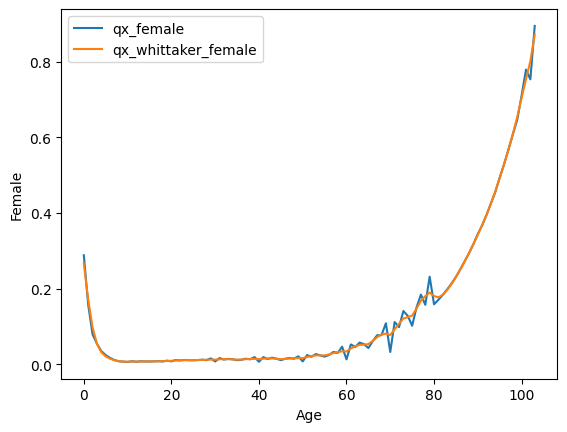

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_3939/1357362636.py:91: RuntimeWarning: divide by zero encountered in divide
  numerator_list = np.log(dx_female.values.reshape(-1, 104) / (L_female.values.reshape(-1, 104) * smoothed_double_female)) * (time_years - reference_year)
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_3939/1357362636.py:91: RuntimeWarning: divide by zero encountered in log
  numerator_list = np.log(dx_female.values.reshape(-1, 104) / (L_female.values.reshape(-1, 104) * smoothed_double_female)) * (time_years - reference_year)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


ValueError: operands could not be broadcast together with shapes (15600,) (104,) 

In [4]:
import pandas as pd
import seaborn as sns
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

def clean(data):
    # Create DataFrame with specified columns
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])
    
    # Split rows and fill DataFrame
    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row
    
    # Clean up data by removing + and - signs
    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    # Convert columns to numeric, set errors='coerce' to handle non-numeric values
    for column in df.columns:
        if column not in ["Year", "Age"]:
            df[column] = pd.to_numeric(df[column], errors='coerce')
    
    # Convert "Year" and "Age" columns to integers, filling NaNs with 0 (if needed)
    df["Year"] = pd.to_numeric(df["Year"], errors='coerce').fillna(0).astype(int)
    df["Age"] = pd.to_numeric(df["Age"], errors='coerce').fillna(0).astype(int)
    
    # Remove duplicates and reset index
    df = df.drop_duplicates(subset=["Year", "Age"]).reset_index(drop=True)
    
    return df

def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Penalty matrix
    P = lambda_ * D.T @ D
    
    # Solve system of equations
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

# Load and clean data
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter="\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter="\t"))

# Align population and death data by trimming extra rows
length_difference = len(italy_population) - len(italy_death)
italy_population = italy_population[:-length_difference].reset_index(drop=True)

# Calculate mortality rates for females and males, replacing NaN with 0
qx_female = (italy_death["Female"] / italy_population["Female"]).fillna(0)
qx_male = (italy_death["Male"] / italy_population["Male"]).fillna(0)

# Use first 111 entries and exclude the last 7 entries for analysis
qx_1841_female = qx_female.head(111)[:-7]
qx_1841_male = qx_male.head(111)[:-7]

# Apply Whittaker-Henderson smoothing
smoothed_qx_female = whittaker_henderson(qx_1841_female, lambda_=1)
smoothed_qx_male = whittaker_henderson(qx_1841_male, lambda_=10)

# Plot the original and smoothed female mortality rate
age = italy_death["Age"].head(104)
sns.lineplot(x=age, y=qx_1841_female, label="qx_female")
sns.lineplot(x=age, y=smoothed_qx_female, label="qx_whittaker_female")
plt.legend()
plt.show()

# Trim death and population data to match the age limit of 104
italy_death = italy_death[italy_death["Age"] < 104].reset_index(drop=True)
italy_population = italy_population[italy_population["Age"] < 104].reset_index(drop=True)

# Calculate numerator for lambda values
dx_female = italy_death["Female"]
L_female = italy_population["Female"]

# Expand smoothed_qx_female for each year (reshape to (150, 104) for years and age groups)
smoothed_double_female = np.tile(smoothed_qx_female, (150, 1))  # Shape becomes (150, 104)
time_years = italy_death["Year"].values.reshape(-1, 104)  # Reshape to match (150, 104)
reference_year = 1872

# Calculate lambda for each age group
numerator_list = np.log(dx_female.values.reshape(-1, 104) / (L_female.values.reshape(-1, 104) * smoothed_double_female)) * (time_years - reference_year)
numerator_sum = numerator_list.sum(axis=0)  # Sum across years for each age
denominator = np.sum((time_years - reference_year) ** 2, axis=0)  # Sum across years for each age
lambda_female = -numerator_sum / denominator

# Calculate alpha values for each year
alpha = []
years = np.arange(0, 150)

for year in years:
    numerator = np.sum((dx_female / (L_female * smoothed_double_female[year])) * np.exp(-lambda_female * year))
    denominator = np.sum(np.exp(-2 * lambda_female * year))
    alpha.append(numerator / denominator)

# Calculate qx_female based on alpha and lambda values
qx_female_final = []

for year in years:
    alpha_year = alpha[year]
    qx_year = alpha_year * smoothed_qx_female * np.exp(-lambda_female * year)
    qx_female_final.extend(qx_year)

# Display the final qx_female values
qx_female_final = np.array(qx_female_final)
qx_female_final[:10]  # Display the first 10 values for inspection
